In [26]:
import numpy as np
import cv2
import math
import matplotlib.pyplot as plt

In [27]:
image = cv2.imread('sar_3.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
image_line = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

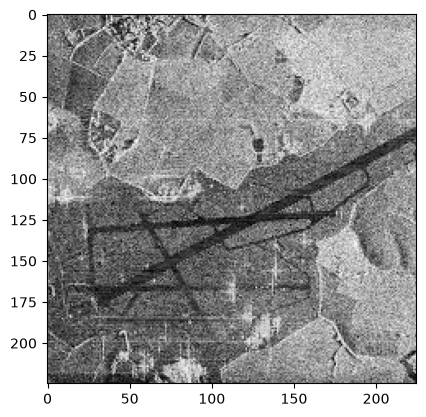

In [29]:
plt.imshow(image_gray, cmap="gray");

# 1. Поиск наиболее протяженного участка для изображения sar_3.jpg (выделение линий при помощи преобразования Хафа)

In [30]:
edges = cv2.Canny(image_gray,130,400,apertureSize = 3)
lines = cv2.HoughLines(edges, 1, np.pi / 180, 100)

In [32]:
rho = lines[0][0][0]
theta = lines[0][0][1]
a = math.cos(theta)
b = math.sin(theta)
x0 = a * rho
y0 = b * rho
pt1 = (int(x0 + 1000*(-b)), int(y0 + 1000*(a)))
pt2 = (int(x0 - 1000*(-b)), int(y0 - 1000*(a)))
cv2.line(image_line, pt1, pt2, (255, 0, 0), 3, cv2.LINE_AA);

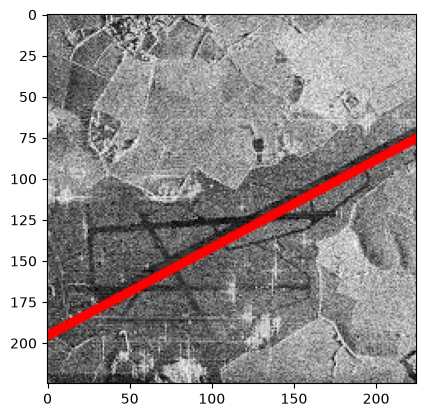

In [34]:
plt.imshow(image_line);

# 2. Исследование алгоритмов бинаризации, выделение участка дорожной полосы для изображения sar_3.jpg

Точечная бинаризация

In [36]:
import copy
bin_img = copy.deepcopy(image_gray)
T  = 80
bin_img[image_gray < T] = 255
bin_img[image_gray >= T] = 0

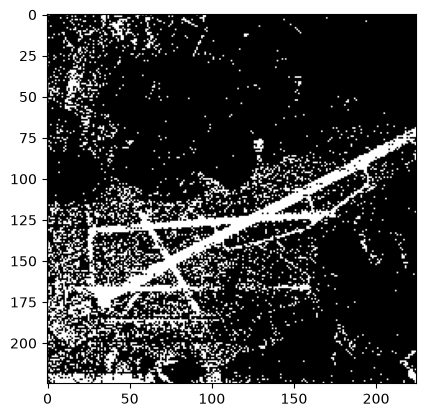

In [38]:
plt.imshow(bin_img, cmap="gray");

Бинаризация Отсу

In [40]:
_,th2 = cv2.threshold(image_gray,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)

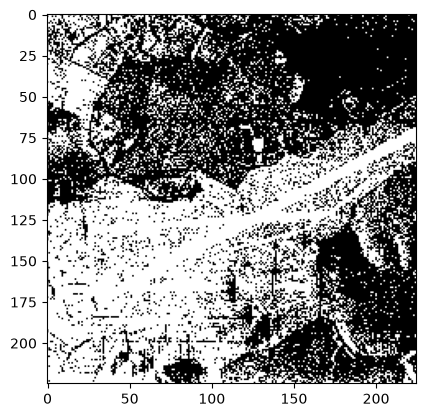

In [42]:
plt.imshow(th2, cmap="gray");

Адаптивная бинаризация

In [43]:
th3 = cv2.adaptiveThreshold(image_gray,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,\
            cv2.THRESH_BINARY_INV,71,15)

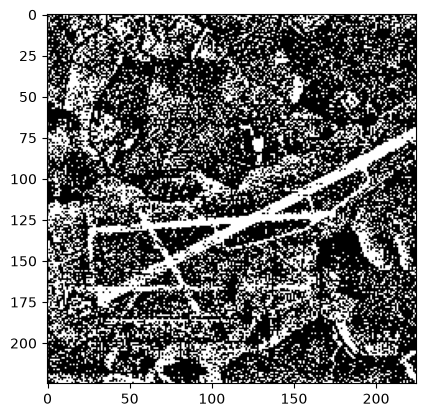

In [44]:
plt.imshow(th3, cmap="gray");

Лучший результат: точненая бинаризация с порогом T=80.

Выделения участка дорожной полосы

In [45]:
blurred = cv2.GaussianBlur(image_gray, (7, 7), 0)
_,road = cv2.threshold(blurred,T,255,cv2.THRESH_BINARY_INV)
contours, _ = cv2.findContours(road, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

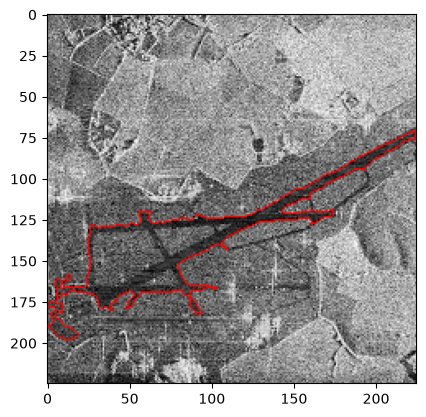

In [47]:
lane_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
for contour in contours:
    area = cv2.contourArea(contour)
    if area > 500:
        cv2.drawContours(lane_image, [contour], -1, (255, 0, 0), 1)
plt.imshow(lane_image);